In [4]:

import os
import warnings
from huggingface_hub.utils import logging as hf_logging

os.environ["HF_HUB_DISABLE_SYMLINKS_WARNING"] = "1"
warnings.filterwarnings("ignore")
hf_logging.set_verbosity_error()

import random
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from datasets import load_dataset
from huggingface_hub import HfApi, ModelCard

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

Using device: cpu


DatasetDict({
    train: Dataset({
        features: ['img', 'label'],
        num_rows: 50000
    })
    test: Dataset({
        features: ['img', 'label'],
        num_rows: 10000
    })
})
Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


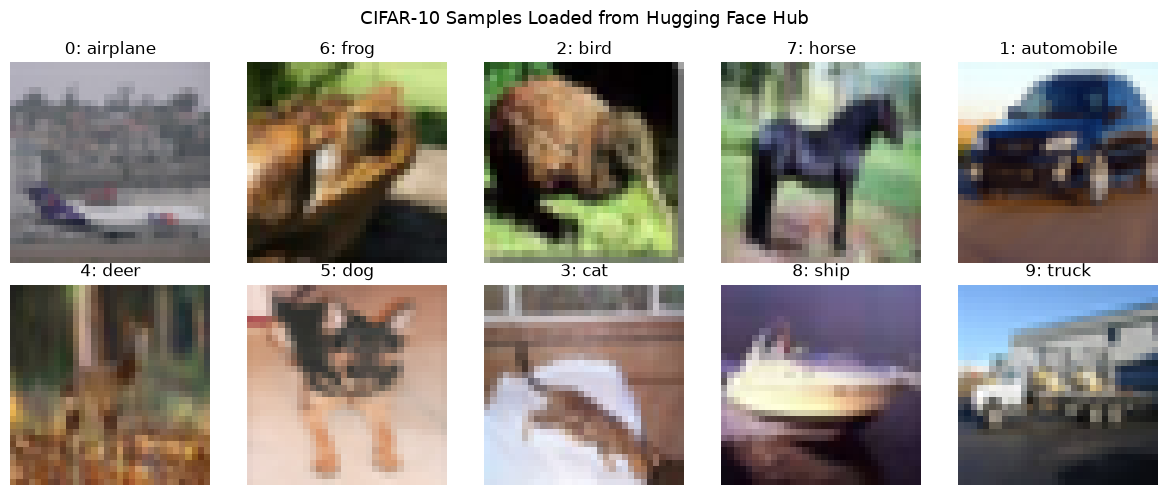


Top 5 CIFAR-10 Image Classification Models on Hugging Face Hub:
 - nateraw/vit-base-patch16-224-cifar10 | Downloads: 4315 | Library: transformers
 - edadaltocg/resnet18_cifar10 | Downloads: 2477 | Library: timm
 - aaraki/vit-base-patch16-224-in21k-finetuned-cifar10 | Downloads: 2117 | Library: transformers
 - AdrianSK/vit-b16-in21k-cifar100 | Downloads: 1183 | Library: pytorch
 - ahsanjavid/convnext-tiny-finetuned-cifar10 | Downloads: 977 | Library: transformers

=== Model Card Metadata (edadaltocg/resnet18_cifar10) ===
{'datasets': 'cifar10', 'language': 'en', 'library_name': 'timm', 'license': 'mit', 'metrics': ['accuracy'], 'tags': ['image-classification', 'resnet18', 'cifar10'], 'model-index': [{'name': 'resnet18_cifar10', 'results': [{'task': {'type': 'image-classification'}, 'dataset': {'name': 'CIFAR-10', 'type': 'cifar10'}, 'metrics': [{'type': 'accuracy', 'value': 0.9498}]}]}]}

=== Model Card Text Preview ===

# Model Card for Model ID

This model is a small resnet18 trained

In [6]:
hf_dataset = load_dataset("uoft-cs/cifar10")
class_names = hf_dataset["train"].features["label"].names

print(hf_dataset)
print("Classes:", class_names)

fig, axes = plt.subplots(2, 5, figsize=(12, 5))
shown = set()
idx = 0
for sample in hf_dataset["train"]:
    lbl = sample["label"]
    if lbl not in shown:
        ax = axes[idx // 5, idx % 5]
        ax.imshow(sample["img"])
        ax.set_title(f"{lbl}: {class_names[lbl]}")
        ax.axis("off")
        shown.add(lbl)
        idx += 1
    if len(shown) == 10:
        break
plt.suptitle("CIFAR-10 Samples Loaded from Hugging Face Hub", fontsize=13)
plt.tight_layout()
plt.show()

api = HfApi()
models = list(api.list_models(search="cifar10", filter="image-classification", sort="downloads", limit=5))
print("\nTop 5 CIFAR-10 Image Classification Models on Hugging Face Hub:")
for m in models:
    print(f" - {m.id} | Downloads: {m.downloads} | Library: {m.library_name}")

model_id = "edadaltocg/resnet18_cifar10"
try:
    card = ModelCard.load(model_id)
    print(f"\n=== Model Card Metadata ({model_id}) ===")
    print(card.data.to_dict())
    print("\n=== Model Card Text Preview ===")
    print(card.text[:600])
except Exception as e:
    print(f"Could not load model card for {model_id}: {e}")

Input shape:      (32, 32)
Conv2D output:    (32, 32)
MaxPool2D output: (16, 16)


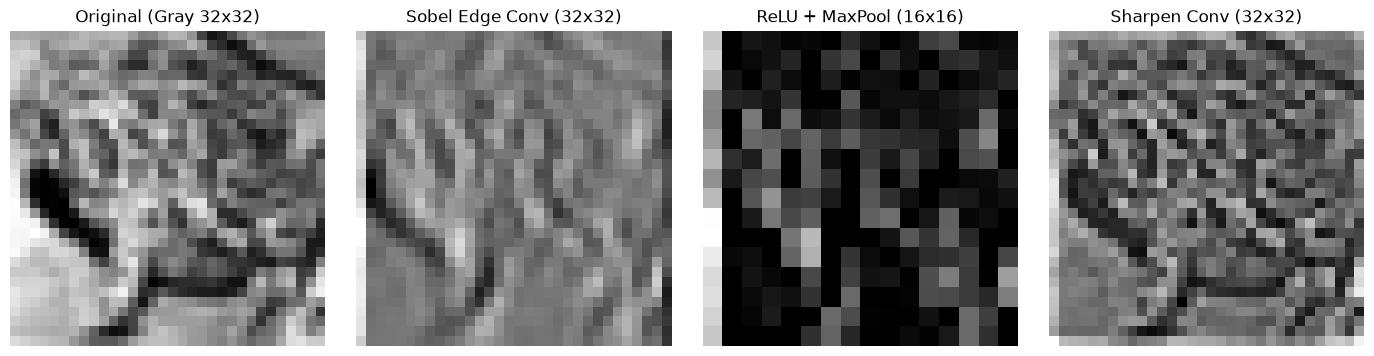

In [7]:
def conv2d_numpy(image, kernel, stride=1, padding=0):
    """2D Convolution on a single-channel (H, W) NumPy array."""
    if padding > 0:
        image = np.pad(image, ((padding, padding), (padding, padding)), mode="constant", constant_values=0)

    H, W = image.shape
    kH, kW = kernel.shape
    out_H = (H - kH) // stride + 1
    out_W = (W - kW) // stride + 1

    output = np.zeros((out_H, out_W), dtype=np.float32)
    for i in range(out_H):
        for j in range(out_W):
            region = image[i * stride : i * stride + kH, j * stride : j * stride + kW]
            output[i, j] = np.sum(region * kernel)
    return output


def max_pool2d_numpy(feature_map, pool_size=2, stride=2):
    """2D Max-Pooling on a single-channel (H, W) NumPy array."""
    H, W = feature_map.shape
    out_H = (H - pool_size) // stride + 1
    out_W = (W - pool_size) // stride + 1

    output = np.zeros((out_H, out_W), dtype=np.float32)
    for i in range(out_H):
        for j in range(out_W):
            region = feature_map[i * stride : i * stride + pool_size, j * stride : j * stride + pool_size]
            output[i, j] = np.max(region)
    return output


sample_img = np.array(hf_dataset["train"][12]["img"], dtype=np.float32) / 255.0
gray_img = np.mean(sample_img, axis=2)

sobel_x = np.array([[-1, 0, 1],
                    [-2, 0, 2],
                    [-1, 0, 1]], dtype=np.float32)

sharpen = np.array([[ 0, -1,  0],
                    [-1,  5, -1],
                    [ 0, -1,  0]], dtype=np.float32)

conv_edge = conv2d_numpy(gray_img, sobel_x, stride=1, padding=1)
relu_edge = np.maximum(0, conv_edge)
pool_edge = max_pool2d_numpy(relu_edge, pool_size=2, stride=2)

conv_sharp = conv2d_numpy(gray_img, sharpen, stride=1, padding=1)

print(f"Input shape:      {gray_img.shape}")
print(f"Conv2D output:    {conv_edge.shape}")
print(f"MaxPool2D output: {pool_edge.shape}")

fig, axes = plt.subplots(1, 4, figsize=(14, 3.5))
titles = ["Original (Gray 32x32)", "Sobel Edge Conv (32x32)", "ReLU + MaxPool (16x16)", "Sharpen Conv (32x32)"]
images = [gray_img, conv_edge, pool_edge, conv_sharp]

for ax, img, title in zip(axes, images, titles):
    ax.imshow(img, cmap="gray")
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()

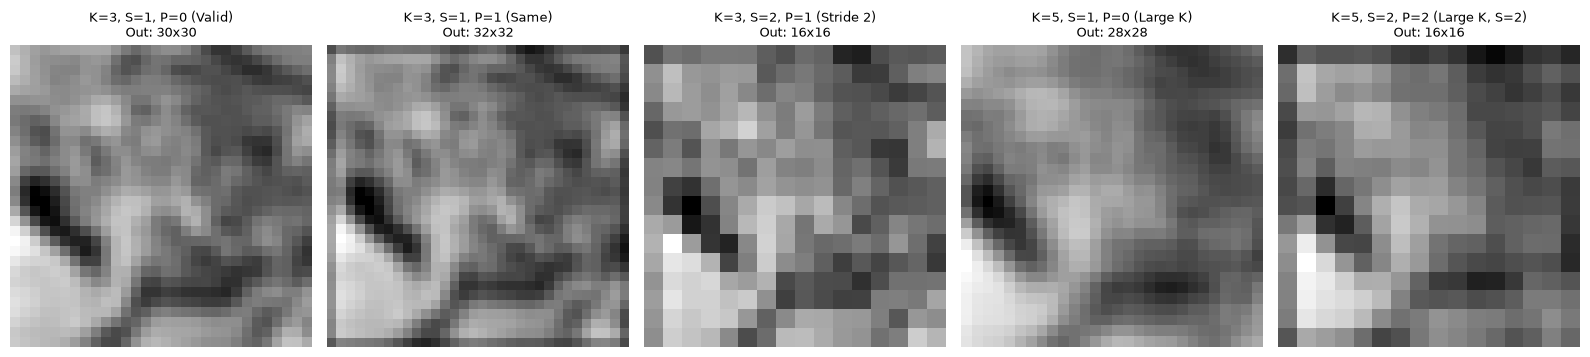

,Configuration,Kernel (K),Stride (S),Padding (P),Expected Shape,Actual Shape
0,"K=3, S=1, P=0 (Valid)",3,1,0,30x30,30x30
1,"K=3, S=1, P=1 (Same)",3,1,1,32x32,32x32
2,"K=3, S=2, P=1 (Stride 2)",3,2,1,16x16,16x16
3,"K=5, S=1, P=0 (Large K)",5,1,0,28x28,28x28
4,"K=5, S=2, P=2 (Large K, S=2)",5,2,2,16x16,16x16


In [8]:
configs = [
    {"name": "K=3, S=1, P=0 (Valid)", "K": 3, "S": 1, "P": 0},
    {"name": "K=3, S=1, P=1 (Same)",  "K": 3, "S": 1, "P": 1},
    {"name": "K=3, S=2, P=1 (Stride 2)", "K": 3, "S": 2, "P": 1},
    {"name": "K=5, S=1, P=0 (Large K)",  "K": 5, "S": 1, "P": 0},
    {"name": "K=5, S=2, P=2 (Large K, S=2)", "K": 5, "S": 2, "P": 2},
]

records = []
fig, axes = plt.subplots(1, len(configs), figsize=(16, 3.5))
H_in, W_in = gray_img.shape

for ax, cfg in zip(axes, configs):
    K, S, P = cfg["K"], cfg["S"], cfg["P"]
    # Simple averaging (blur) kernel of size K x K
    kernel = np.ones((K, K), dtype=np.float32) / (K * K)
    out = conv2d_numpy(gray_img, kernel, stride=S, padding=P)

    expected_dim = (H_in - K + 2 * P) // S + 1
    records.append({
        "Configuration": cfg["name"],
        "Kernel (K)": K,
        "Stride (S)": S,
        "Padding (P)": P,
        "Expected Shape": f"{expected_dim}x{expected_dim}",
        "Actual Shape": f"{out.shape[0]}x{out.shape[1]}",
    })

    ax.imshow(out, cmap="gray")
    ax.set_title(f"{cfg['name']}\nOut: {out.shape[0]}x{out.shape[1]}", fontsize=9)
    ax.axis("off")

plt.tight_layout()
plt.show()

df_ksp = pd.DataFrame(records)
display(df_ksp)

Epoch 01/8 | Train Loss: 1.6731, Acc: 38.52% | Test Loss: 1.3799, Acc: 49.50%
Epoch 02/8 | Train Loss: 1.3246, Acc: 51.74% | Test Loss: 1.2115, Acc: 55.45%
Epoch 03/8 | Train Loss: 1.1445, Acc: 58.99% | Test Loss: 1.1118, Acc: 59.60%
Epoch 04/8 | Train Loss: 1.0420, Acc: 62.87% | Test Loss: 1.2067, Acc: 58.15%
Epoch 05/8 | Train Loss: 0.9690, Acc: 65.24% | Test Loss: 0.9800, Acc: 65.15%
Epoch 06/8 | Train Loss: 0.9116, Acc: 68.02% | Test Loss: 1.0311, Acc: 64.40%
Epoch 07/8 | Train Loss: 0.8554, Acc: 69.95% | Test Loss: 0.9935, Acc: 66.35%
Epoch 08/8 | Train Loss: 0.7897, Acc: 72.49% | Test Loss: 0.9190, Acc: 69.20%

Training complete in 88.0s


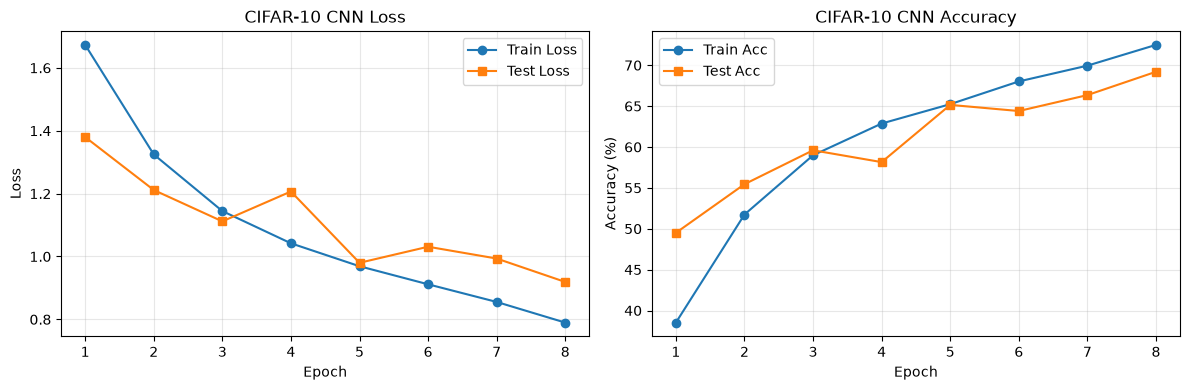

In [9]:
class HFCIFAR10Dataset(Dataset):
    def __init__(self, hf_split, transform=None):
        self.data = hf_split
        self.transform = transform

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        item = self.data[idx]
        img = item["img"]
        label = item["label"]
        if self.transform:
            img = self.transform(img)
        return img, label


train_tf = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616)),
])

test_tf = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616)),
])

# Use a balanced subset for fast CPU execution (increase if using GPU)
train_subset = hf_dataset["train"].shuffle(seed=SEED).select(range(10000))
test_subset = hf_dataset["test"].shuffle(seed=SEED).select(range(2000))

train_loader = DataLoader(HFCIFAR10Dataset(train_subset, train_tf), batch_size=64, shuffle=True)
test_loader = DataLoader(HFCIFAR10Dataset(test_subset, test_tf), batch_size=128, shuffle=False)


class BasicCNN(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()
        self.features = nn.Sequential(
            # Block 1: 32x32 -> 16x16
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),

            # Block 2: 16x16 -> 8x8
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),

            # Block 3: 8x8 -> 4x4
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 4 * 4, 256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, num_classes),
        )

    def forward(self, x):
        return self.classifier(self.features(x))


model = BasicCNN().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

epochs = 8
history = {"train_loss": [], "test_loss": [], "train_acc": [], "test_acc": []}

start = time.time()
for epoch in range(1, epochs + 1):
    model.train()
    tr_loss, tr_correct, tr_total = 0.0, 0, 0
    for imgs, labels in train_loader:
        imgs, labels = imgs.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(imgs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        tr_loss += loss.item() * imgs.size(0)
        tr_correct += (outputs.argmax(1) == labels).sum().item()
        tr_total += labels.size(0)

    model.eval()
    te_loss, te_correct, te_total = 0.0, 0, 0
    with torch.no_grad():
        for imgs, labels in test_loader:
            imgs, labels = imgs.to(device), labels.to(device)
            outputs = model(imgs)
            loss = criterion(outputs, labels)
            te_loss += loss.item() * imgs.size(0)
            te_correct += (outputs.argmax(1) == labels).sum().item()
            te_total += labels.size(0)

    history["train_loss"].append(tr_loss / tr_total)
    history["test_loss"].append(te_loss / te_total)
    history["train_acc"].append(100.0 * tr_correct / tr_total)
    history["test_acc"].append(100.0 * te_correct / te_total)

    print(f"Epoch {epoch:02d}/{epochs} | "
          f"Train Loss: {history['train_loss'][-1]:.4f}, Acc: {history['train_acc'][-1]:.2f}% | "
          f"Test Loss: {history['test_loss'][-1]:.4f}, Acc: {history['test_acc'][-1]:.2f}%")

print(f"\nTraining complete in {time.time() - start:.1f}s")

# Plot Loss and Accuracy Curves
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(range(1, epochs + 1), history["train_loss"], marker="o", label="Train Loss")
ax1.plot(range(1, epochs + 1), history["test_loss"], marker="s", label="Test Loss")
ax1.set_title("CIFAR-10 CNN Loss")
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Loss")
ax1.legend()
ax1.grid(True, alpha=0.3)

ax2.plot(range(1, epochs + 1), history["train_acc"], marker="o", label="Train Acc")
ax2.plot(range(1, epochs + 1), history["test_acc"], marker="s", label="Test Acc")
ax2.set_title("CIFAR-10 CNN Accuracy")
ax2.set_xlabel("Epoch")
ax2.set_ylabel("Accuracy (%)")
ax2.legend()
ax2.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()